# EDA 4 — H2: covariables del hogar y la brecha entre el aviso y la denuncia

**Qué decide este notebook.** Es el soporte de **H2**, la última hipótesis abierta del caso (D4) y la que se presenta el 31 de octubre:

> **H2.** En violencia familiar, la brecha llamadas/carpeta por AGEB **disminuye** con la escolaridad (`GRAPROES`) y la derechohabiencia (`PDER_SS`), y **aumenta** con el hacinamiento (`PRO_OCUP_C`).

Se construye en dos pasos, en dos secciones separadas y en este orden:

| Sección | Experimento | Qué hace | Salida |
|---|---|---|---|
| 1–5 | **2.2** | Une RESAGEBURB 2020 con el universo de `11_`, describe las tres covariables, cuenta los `*` de confidencialidad y los ceros, aplica las exclusiones de S5 y mide **cuánta carpeta se va con ellas**. Reporta **VIF y la matriz de correlación entre covariables** | `resultados/12_ageb_covariables_resageburb.csv` |
| 6+ | **3.1** | La regresión de H2 con errores espaciales, las cinco sensibilidades y el placebo espacial | `resultados/16_h2_regresion_brecha_covariables.csv` |

**En esta corrida solo está el 2.2.** La separación es deliberada y es la misma disciplina del 5, el 8 y el 11 de octubre: **primero se fija la regla, después se mira el resultado**.

> ⚠️ **En las secciones 1–5 no se calcula ninguna asociación entre las covariables y la brecha.** Ni una correlación, ni un gráfico de dispersión, ni una tabla cruzada por clase de brecha. La columna de la brecha se arrastra en el CSV porque el 3.1 la necesita, pero aquí no se usa para nada más que contar unidades. Si se mirara esa asociación ahora, la regla del §3 de `PLAN_31_OCT.md` dejaría de ser una predicción.

**La regla de decisión quedó fijada el 16 de octubre de 2026** en `PLAN_31_OCT.md` §3, antes de ejecutar esta celda. En resumen, y por si el plan no está a la mano:
- **Escala y modelo:** log de la brecha (= logit empírico de llamadas/(llamadas+carpetas), corrección de 0.5), covariables estandarizadas, efecto fijo de ventana, MCP con pesos 1/(σ̂²_AGEB + v) donde v = 1/(llamadas+0.5) + 1/(carpetas+0.5) es la varianza binomial **conocida**.
- **Errores estándar:** espacialmente robustos tipo Conley, kernel de Bartlett, **ancho de banda 2 km**, elegido porque el correlograma del 2.5 sitúa la dependencia en 1–2 km y la encuentra en cero a partir de ahí. No por conveniencia.
- **Veredicto por covariable:** se **acepta** si el signo es el predicho, el IC 95% espacial excluye el cero y el signo se mantiene en las cinco sensibilidades; se **rechaza** si el IC excluye el cero con el signo contrario; **no concluye** si incluye el cero o el signo cambia entre variantes. Los tres desenlaces están previstos y los tres se reportan.
- **Declarado de antemano:** se espera un R² pequeño. Con mosaico de barrio a 1–2 km (I de Moran corregido 0.245), tres covariables de AGEB no van a explicar la brecha. **El R² no es el criterio**; el criterio es el signo con un intervalo honesto.

**Supuestos que aplican aquí** (formato del criterio transversal — *por qué es válido en este contexto*, no *qué se hizo*):
- **S5 (falacia ecológica y denominador).** Uso las covariables de RESAGEBURB como descriptores de los hogares del AGEB y las viviendas particulares habitadas como denominador, asumiendo que el AGEB del hecho es el del domicilio —en violencia familiar el hecho ocurre en la vivienda, y en las dos fuentes la coordenada es la del lugar— y que los hogares afectados se parecen al promedio de su AGEB. Si la violencia se concentrara en subgrupos dentro del AGEB, **H2 se lee como asociación territorial y no individual**; la inferencia individual solo la da la ENDIREH, que no baja a AGEB.
- **S6 (la brecha no es el subregistro).** La brecha mezcla la propensión a *llamar* con la propensión a *denunciar*. Si las covariables movieran la primera, H2 estaría midiendo dos mecanismos a la vez. Control pendiente y declarado como trabajo futuro: las llamadas de otros motivos en el mismo AGEB como proxy de la propensión a llamar.
- **Nada de esto es causal.** Tres covariables del Censo 2020 sobre dos ventanas de datos administrativos no identifican ningún efecto. El verbo es **se asocia**.

**Lo que este notebook no recalcula:** la brecha, los conteos de llamadas y carpetas, los grupos de H3 y las clasificaciones vienen de `resultados/11_` (experimento 2.1, congelado el 11 de oct). Los componentes de varianza vienen de `resultados/13_` (experimento 2.3). El diagnóstico espacial viene de `resultados/15_` (experimento 2.5).

In [1]:
import io, unicodedata, warnings, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 120, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd() if (Path.cwd() / "carpetas-datos").exists() else Path.cwd().parent
OUT = ROOT / "resultados"; OUT.mkdir(exist_ok=True)
AGEB_ZIP = ROOT / "AGEB" / "ageb_mza_urbana_09_cpv2020_csv.zip"

SEMILLA = 2026                       # la misma de todo el caso
RNG = np.random.default_rng(SEMILLA)
VENT = ["2019", "2021-22"]
MIN_VIV = 50                         # S5 / 2.5: por debajo de 50 viviendas las tasas no se mapean
SIN_POLIGONO = {"0901101101107", "0901201351227"}   # no tienen polígono ni alcaldía en el shapefile

def norm(s):
    # Normaliza nombres de alcaldía (sin acentos, mayúsculas) para que los joins entre fuentes cuadren
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return " ".join(s.upper().split())

print("ROOT:", ROOT)
print("zip RESAGEBURB existe:", AGEB_ZIP.exists())

ROOT: /Users/emilianosandoval/Documents/code/caso_titulacion
zip RESAGEBURB existe: True


## 1. El universo: qué AGEB entran y de dónde salen

El universo primario de H2 es el mismo de H1, para que las dos hipótesis hablen de las mismas unidades: **AGEB con al menos una carpeta de violencia familiar en cada ventana**. Son 2,294 de los 2,433 AGEB urbanos de la CDMX, y están así desde el experimento 2.3.

*Por qué ese universo y no todos los AGEB:* la brecha es una razón y necesita denominador en las dos ventanas. Un AGEB con cero carpetas en una ventana no tiene brecha definida ahí, y rellenarlo con cero o con la media de la ciudad inventaría la variación que H2 quiere explicar.

In [2]:
brecha = pd.read_csv(OUT / "11_ageb_brecha_por_delito.csv", dtype={"ageb": str})
vf = brecha[brecha["delito"] == "violencia_familiar"].copy()
print("filas de violencia familiar en 11_:", len(vf), "| AGEB únicos:", vf["ageb"].nunique(), "| ventanas:", sorted(vf["ventana"].unique()))

# Universo de H1/H2: >= 1 carpeta en cada ventana
carp = vf.pivot_table(index="ageb", columns="ventana", values="carpetas", aggfunc="first")
universo = carp.index[(carp[VENT] >= 1).all(axis=1)]
print("AGEB con >= 1 carpeta en ambas ventanas (universo primario):", len(universo))

# Universo de conteo alto, que es la sensibilidad V1
alto = carp.index[(carp[VENT] >= 12).all(axis=1)]
print("AGEB con >= 12 carpetas en ambas ventanas (V1, conteo alto):", len(alto))

carpetas_totales = vf["carpetas"].sum()
print(f"carpetas de violencia familiar en las dos ventanas: {carpetas_totales:,.0f}")

filas de violencia familiar en 11_: 4866 | AGEB únicos: 2433 | ventanas: ['2019', '2021-22']
AGEB con >= 1 carpeta en ambas ventanas (universo primario): 2294
AGEB con >= 12 carpetas en ambas ventanas (V1, conteo alto): 698
carpetas de violencia familiar en las dos ventanas: 53,316


## 2. RESAGEBURB 2020: lectura y las tres covariables

**Trampas de la fuente** (documentadas en `CLAUDE.md`): el CSV mezcla manzanas y totales, así que el renglón del AGEB es `MZA == "000"` con `AGEB != "0000"`; se lee con `dtype=str` y `encoding="utf-8-sig"` porque trae BOM; y el asterisco `*` **no es cero**, es dato reservado por confidencialidad. La clave `ENTIDAD+MUN+LOC+AGEB` une 100% con la columna `ageb` del shapefile y de `11_`.

**Las tres covariables, y por qué estas:**

| Covariable | Variable de RESAGEBURB | Cómo se usa | Qué representa en H2 |
|---|---|---|---|
| Escolaridad | `GRAPROES` | tal cual (grados promedio de escolaridad) | Capacidad de navegar un trámite: la denuncia exige levantar una carpeta, no solo pedir ayuda |
| Derechohabiencia | `PDER_SS` / `POBTOT` | **como proporción**, porque `PDER_SS` es un conteo de personas | Contacto previo con una institución del Estado, como proxy de costo de acceso |
| Hacinamiento | `PRO_OCUP_C` | tal cual (promedio de ocupantes por cuarto) | Exposición y falta de privacidad para denunciar desde la propia vivienda |
| Denominador | `VIVPAR_HAB` | tal cual | Viviendas particulares habitadas; define las exclusiones de S5 |

*Supuesto de medición:* uso `PDER_SS` como proporción de la población total asumiendo que lo que importa es la **prevalencia** de la derechohabiencia en el AGEB y no su volumen; si se usara el conteo crudo, la covariable sería en gran medida un proxy del tamaño del AGEB y H2 estaría midiendo población, no carencia.

*Supuesto temporal:* uso el Censo 2020 para describir dos ventanas, 2019 y jul-2021 → abr-2022, asumiendo que la composición socioeconómica de un AGEB se mueve poco en tres años. Si hubiera cambiado mucho en algunos AGEB (desarrollo inmobiliario, por ejemplo), la covariable tendría error de medición y el coeficiente estaría **atenuado hacia cero**, es decir, el sesgo iría en contra de H2 y no a su favor.

In [3]:
z = zipfile.ZipFile(AGEB_ZIP)
nombre = [n for n in z.namelist() if n.endswith("conjunto_de_datos_ageb_urbana_09_cpv2020.csv")][0]
res = pd.read_csv(io.BytesIO(z.read(nombre)), dtype=str, encoding="utf-8-sig", low_memory=False)
print("RESAGEBURB crudo:", res.shape)

# El renglón de AGEB, no de manzana
ag = res[(res["MZA"] == "000") & (res["AGEB"] != "0000")].copy()
ag["ageb"] = ag["ENTIDAD"] + ag["MUN"] + ag["LOC"] + ag["AGEB"]
print("renglones de AGEB:", len(ag), "| claves únicas:", ag["ageb"].nunique())

# El '*' es confidencialidad, no cero: se convierte a NaN explícitamente y se cuenta
VARS = ["GRAPROES", "PDER_SS", "PRO_OCUP_C", "VIVPAR_HAB", "POBTOT"]
conf = pd.DataFrame({v: [(ag[v] == "*").sum(), (ag[v] == "N/D").sum()] for v in VARS},
                    index=["reservado '*'", "'N/D'"])
display(conf)

for v in VARS:
    ag[v] = pd.to_numeric(ag[v].replace({"*": np.nan, "N/D": np.nan}), errors="coerce")

ag["pct_der_ss"] = np.where(ag["POBTOT"] > 0, ag["PDER_SS"] / ag["POBTOT"], np.nan)

cov = ag[["ageb", "GRAPROES", "pct_der_ss", "PRO_OCUP_C", "VIVPAR_HAB", "POBTOT", "PDER_SS"]].copy()
COVS = ["GRAPROES", "pct_der_ss", "PRO_OCUP_C"]

# La unión con 11_ tiene que ser perfecta: si no, hay que parar y no seguir
faltan = set(vf["ageb"].unique()) - set(cov["ageb"])
print("AGEB de 11_ que no están en RESAGEBURB:", len(faltan), sorted(faltan)[:5])
assert len(faltan) == 0, "la clave ENTIDAD+MUN+LOC+AGEB dejó de unir al 100%: revisar antes de seguir"

RESAGEBURB crudo: (68941, 230)
renglones de AGEB: 2433 | claves únicas: 2433


,GRAPROES,PDER_SS,PRO_OCUP_C,VIVPAR_HAB,POBTOT
reservado '*',10,11,10,12,0
'N/D',0,0,0,0,0


AGEB de 11_ que no están en RESAGEBURB: 0 []


## 3. Descriptivos de las covariables

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,faltantes
GRAPROES,"2,286.0000",11.5977,1.9996,0.0000,7.5935,9.2000,10.3500,11.3650,13.0550,14.8000,15.3945,16.0700,8
pct_der_ss,"2,272.0000",0.7290,0.0747,0.0000,0.5277,0.6133,0.6903,0.7345,0.7742,0.8326,0.8762,0.9999,22
PRO_OCUP_C,"2,286.0000",0.8107,0.2107,0.0000,0.4400,0.5100,0.6500,0.8200,0.9500,1.1200,1.2815,3.0000,8
VIVPAR_HAB,"2,284.0000","1,113.7487",657.6168,0.0000,9.0000,236.1500,656.0000,"1,007.0000","1,426.7500","2,393.5500","3,096.5900","6,297.0000",10
POBTOT,"2,294.0000","3,922.1944","2,401.5445",0.0000,19.8600,751.0000,"2,242.2500","3,534.5000","5,131.2500","8,305.7500","11,588.6100","21,198.0000",0


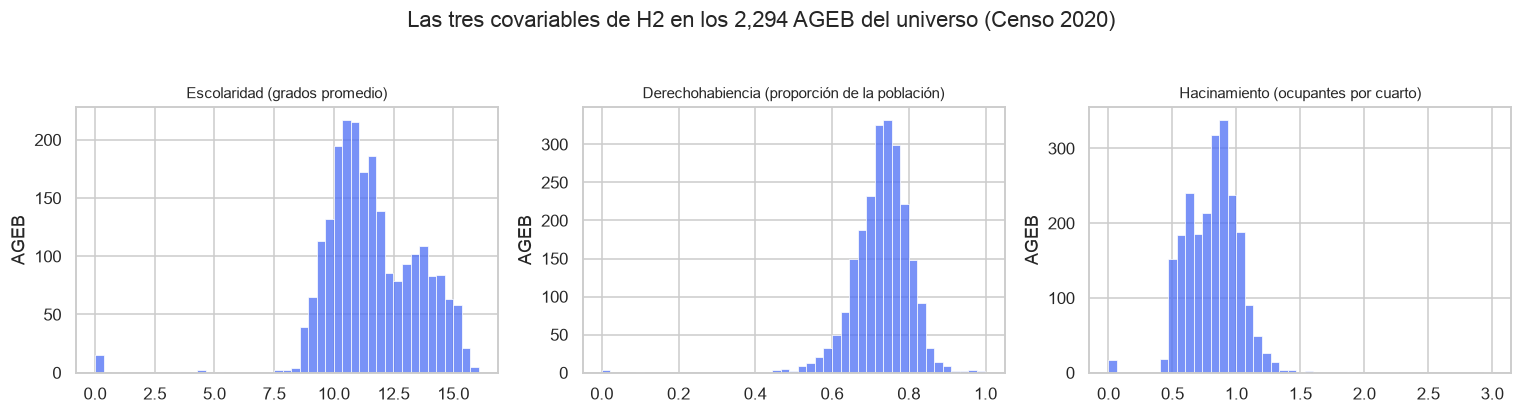

In [4]:
desc = cov.loc[cov["ageb"].isin(universo), COVS + ["VIVPAR_HAB", "POBTOT"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["faltantes"] = cov.loc[cov["ageb"].isin(universo), COVS + ["VIVPAR_HAB", "POBTOT"]].isna().sum()
display(desc)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
etiquetas = {"GRAPROES": "Escolaridad (grados promedio)",
             "pct_der_ss": "Derechohabiencia (proporción de la población)",
             "PRO_OCUP_C": "Hacinamiento (ocupantes por cuarto)"}
for ax, v in zip(axes, COVS):
    sns.histplot(cov.loc[cov["ageb"].isin(universo), v].dropna(), bins=45, ax=ax, color="#4c6ef5")
    ax.set_title(etiquetas[v], fontsize=10); ax.set_xlabel(""); ax.set_ylabel("AGEB")
fig.suptitle(f"Las tres covariables de H2 en los {len(universo):,} AGEB del universo (Censo 2020)", y=1.04)
plt.tight_layout(); plt.show()

## 4. Exclusiones de S5, y cuánta carpeta se va con ellas

Las exclusiones se fijaron en `PLAN_31_OCT.md` §3.3 **antes** de ver cualquier resultado. Son tres y cada una tiene su razón:

1. **Viviendas particulares habitadas en 0 o reservadas con `*`.** Sin denominador no hay tasa y, más importante, un AGEB sin viviendas habitadas no tiene hogares que las covariables puedan describir.
2. **Menos de 50 viviendas habitadas.** El 2.5 mostró que ahí la tasa llega a 7,250 carpetas por 1,000 viviendas contra un p99 de 44: son AGEB comerciales o institucionales donde el hecho ocurre pero la gente no vive.
3. **Covariable reservada por confidencialidad.** El `*` no se imputa; el AGEB sale.

Lo que hay que reportar no es el número de AGEB excluidos sino **la fracción de carpetas que se va con ellos**. Si fuera grande, las exclusiones estarían decidiendo el resultado.

In [5]:
u = cov[cov["ageb"].isin(universo)].copy()
carp_u = carp.loc[universo, VENT].sum(axis=1).rename("carpetas_2v")
u = u.merge(carp_u, left_on="ageb", right_index=True, how="left")

u["excl_sin_poligono"] = u["ageb"].isin(SIN_POLIGONO)
u["excl_viv_cero"]     = u["VIVPAR_HAB"].fillna(0).eq(0)
u["excl_viv_reserv"]   = u["VIVPAR_HAB"].isna()
u["excl_viv_menor50"]  = u["VIVPAR_HAB"].between(1, MIN_VIV - 1)
u["excl_cov_reserv"]   = u[COVS].isna().any(axis=1)
MOT = ["excl_sin_poligono", "excl_viv_cero", "excl_viv_reserv", "excl_viv_menor50", "excl_cov_reserv"]
u["excluido"] = u[MOT].any(axis=1)

tab = pd.DataFrame({
    "AGEB": [u[m].sum() for m in MOT] + [u["excluido"].sum()],
    "carpetas": [u.loc[u[m], "carpetas_2v"].sum() for m in MOT] + [u.loc[u["excluido"], "carpetas_2v"].sum()],
}, index=[m.replace("excl_", "") for m in MOT] + ["TOTAL (sin doble conteo)"])
tab["% de las carpetas del universo"] = tab["carpetas"] / u["carpetas_2v"].sum()
display(tab)

est = u[~u["excluido"]].copy()
print(f"universo primario:           {len(u):,} AGEB")
print(f"universo de estimación H2:   {len(est):,} AGEB  ({len(est)/len(u):.1%})")
print(f"carpetas conservadas:        {est['carpetas_2v'].sum():,.0f} de {u['carpetas_2v'].sum():,.0f}  ({est['carpetas_2v'].sum()/u['carpetas_2v'].sum():.2%})")
print(f"universo de estimación V1 (conteo alto): {est['ageb'].isin(alto).sum():,} AGEB")

,AGEB,carpetas,% de las carpetas del universo
sin_poligono,0,0,0.0000
viv_cero,25,249,0.0047
viv_reserv,10,77,0.0015
viv_menor50,19,229,0.0043
cov_reserv,22,272,0.0051
TOTAL (sin doble conteo),44,478,0.0090


universo primario:           2,294 AGEB
universo de estimación H2:   2,250 AGEB  (98.1%)
carpetas conservadas:        52,572 de 53,050  (99.10%)
universo de estimación V1 (conteo alto): 696 AGEB


## 5. Colinealidad entre covariables

Las tres covariables miden facetas de la misma cosa y por eso están correlacionadas. Esto hay que medirlo **antes** de la regresión, porque la regla del §3.4 depende de él: si algún VIF supera 5, el veredicto de H2 se lee sobre las tres regresiones de una sola covariable y no sobre la conjunta, y eso se declara.

Ojo con lo que **no** es esto: la matriz es entre covariables. No incluye la brecha.

In [6]:
corr = est[COVS].corr(method="pearson")
display(corr.rename(index=etiquetas, columns=etiquetas))

# VIF por la vía directa: 1/(1-R²) de cada covariable contra las otras dos
X = est[COVS].to_numpy(float)
X = (X - X.mean(0)) / X.std(0)
vif = {}
for j, v in enumerate(COVS):
    otros = np.delete(X, j, axis=1)
    A = np.column_stack([np.ones(len(otros)), otros])
    beta, *_ = np.linalg.lstsq(A, X[:, j], rcond=None)
    r2 = 1 - ((X[:, j] - A @ beta) ** 2).sum() / ((X[:, j] - X[:, j].mean()) ** 2).sum()
    vif[v] = 1 / (1 - r2)
vif = pd.Series(vif, name="VIF").to_frame()
vif["R² contra las otras dos"] = 1 - 1 / vif["VIF"]
display(vif)
print("VIF máximo:", f"{vif['VIF'].max():.2f}", "| regla: si > 5, el veredicto se lee sobre las tres regresiones simples (PLAN_31_OCT.md §3.4)")

,Escolaridad (grados promedio),Derechohabiencia (proporción de la población),Hacinamiento (ocupantes por cuarto)
Escolaridad (grados promedio),1.0000,0.5929,-0.9308
Derechohabiencia (proporción de la población),0.5929,1.0000,-0.6121
Hacinamiento (ocupantes por cuarto),-0.9308,-0.6121,1.0000


,VIF,R² contra las otras dos
GRAPROES,7.5361,0.8673
pct_der_ss,1.6095,0.3787
PRO_OCUP_C,7.8160,0.8721


VIF máximo: 7.82 | regla: si > 5, el veredicto se lee sobre las tres regresiones simples (PLAN_31_OCT.md §3.4)


## 6. Exportación: `12_ageb_covariables_resageburb.csv`

Una fila por AGEB del universo primario, con las covariables, el denominador, las banderas de exclusión y las dos columnas de universo (primario y conteo alto). El 3.1 lee este archivo y no vuelve a tocar RESAGEBURB.

In [7]:
exp = est_todo = u.copy()
exp["universo_primario"] = True
exp["universo_conteo_alto"] = exp["ageb"].isin(alto)
exp["universo_estimacion_h2"] = ~exp["excluido"]
exp["alcaldia"] = exp["ageb"].map(vf.drop_duplicates("ageb").set_index("ageb")["alcaldia"])

cols = (["ageb", "alcaldia", "carpetas_2v"] + COVS + ["PDER_SS", "POBTOT", "VIVPAR_HAB"]
        + MOT + ["excluido", "universo_primario", "universo_conteo_alto", "universo_estimacion_h2"])
exp = exp[cols].sort_values("ageb")
for c in COVS + ["carpetas_2v"]:
    exp[c] = exp[c].round(4)

ruta = OUT / "12_ageb_covariables_resageburb.csv"
exp.to_csv(ruta, index=False)
print("escrito:", ruta, exp.shape)
display(exp.head(8))
sorted(p.name for p in OUT.glob("*.csv"))

escrito: /Users/emilianosandoval/Documents/code/caso_titulacion/resultados/12_ageb_covariables_resageburb.csv (2294, 18)


,ageb,alcaldia,carpetas_2v,GRAPROES,pct_der_ss,PRO_OCUP_C,PDER_SS,POBTOT,VIVPAR_HAB,excl_sin_poligono,excl_viv_cero,excl_viv_reserv,excl_viv_menor50,excl_cov_reserv,excluido,universo_primario,universo_conteo_alto,universo_estimacion_h2
3,0900200010010,AZCAPOTZALCO,18,11.5200,0.8106,0.7800,"2,580.0000",3183,860.0000,False,False,False,False,False,False,True,False,True
30,0900200010025,AZCAPOTZALCO,7,10.7300,0.8132,0.7600,"4,548.0000",5593,"1,637.0000",False,False,False,False,False,False,True,False,True
82,090020001003A,AZCAPOTZALCO,15,10.5500,0.7877,0.7900,"3,336.0000",4235,"1,179.0000",False,False,False,False,False,False,True,False,True
116,0900200010044,AZCAPOTZALCO,23,11.0700,0.8188,0.7300,"3,904.0000",4768,"1,364.0000",False,False,False,False,False,False,True,False,True
163,0900200010097,AZCAPOTZALCO,14,11.7400,0.8208,0.6900,"1,786.0000",2176,590.0000,False,False,False,False,False,False,True,False,True
189,090020001010A,AZCAPOTZALCO,16,11.8000,0.8030,0.6600,"2,687.0000",3346,880.0000,False,False,False,False,False,False,True,False,True
228,0900200010114,AZCAPOTZALCO,50,11.2100,0.7777,0.8600,"7,673.0000",9866,"2,973.0000",False,False,False,False,False,False,True,True,True
280,0900200010129,AZCAPOTZALCO,46,12.4300,0.8415,0.7200,"4,799.0000",5703,"1,795.0000",False,False,False,False,False,False,True,True,True


['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '12_ageb_covariables_resageburb.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv',
 '15_diagnostico_ageb.csv']

## 7. Qué queda listo y qué sigue

**Lo que deja el 2.2.** Las tres covariables de H2 unidas al universo de H1 sin pérdida de clave, con las exclusiones de S5 aplicadas y cuantificadas en carpetas —no en AGEB—, y con la colinealidad medida antes de estimar nada.

**Lo que explícitamente no se hizo aquí, y es a propósito:** no se miró ninguna asociación entre las covariables y la brecha. Ese es el 3.1, y su regla ya está escrita en `PLAN_31_OCT.md` §3, fijada el 16 de octubre.

**Lo que sigue (3.1, 17–18 de oct):**
1. Regresión primaria: MCP con pesos 1/(σ̂²_AGEB + v) y errores espaciales tipo Conley a 2 km.
2. Las cinco sensibilidades: V1 conteo alto · V2 brecha con 19% de robo descontado (S1) · V3 efectos fijos de alcaldía · V4 MCO sin pesos · V5 bootstrap por bloques sobre los 76 grupos del H3.
3. Placebo espacial: 1,000 permutaciones de las covariables **restringidas dentro de alcaldía**, semilla 2026, para que la nula conserve la estructura espacial que el 2.5 midió.
4. Veredicto por covariable, con los tres desenlaces previstos, y exportación a `16_h2_regresion_brecha_covariables.csv`.